# Day 26 / 100 — DowntimeReason Miner

**Research-grade Kaggle notebook | industrial maintenance NLP + annotated logbook + PIADE**

The three datasets answer **different questions**; this notebook **does not merge rows across domains**. Industrial Maintenance Synthetic provides free-text work orders with **no verified root-cause ground truth**. The annotated maintenance logbook is used for supervised categorization **only if actual labels meet quality and support checks**. PIADE provides production events / alarms and is used for operational downtime frequency, **not causal attribution**.

**Reproducibility contract:** input files read-only; random state 42; exact train/validation/test row identities saved; training-only fitting for vectorizers and supervised models; no use of action/repair descriptions as features when predicting the problem category; test used once after selection; output metrics never hard-coded. `COIN` is not used here: it belongs to Day 30 (instructional video).

In [1]:
from __future__ import annotations
import json, os, re, sys, time, hashlib, zipfile, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, silhouette_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import joblib

SEED=42
INPUT_ROOT=Path('/kaggle/input/datasets/wafabila/downtimereason-dataset')
OUT=Path('/kaggle/working/downtimereason_day26')
for d in ['reports','plots','models','examples','features']:(OUT/d).mkdir(parents=True,exist_ok=True)
R,P,M,F=tuple(OUT/x for x in ['reports','plots','models','features'])
CFG={'industrial_max_texts':120000,'industrial_clusters':12,'industrial_min_df':5,'industrial_max_features':25000,'logbook_min_class_count':30,'logbook_max_classes':12,'piade_chunksize':100000,'seed':SEED}
np.random.seed(SEED)
print('Python',sys.version.split()[0], 'pandas',pd.__version__, 'input exists:',INPUT_ROOT.is_dir())
if not INPUT_ROOT.is_dir():
 print('Mounted:',list(Path('/kaggle/input').iterdir()) if Path('/kaggle/input').is_dir() else [])
 raise FileNotFoundError(INPUT_ROOT)
(R/'config.json').write_text(json.dumps({'input':str(INPUT_ROOT),'cfg':CFG},indent=2))

Python 3.13.15 pandas 2.3.3 input exists: True


332

## 01 — Inventory, manifest, provenance

The Kaggle upload should contain `industrial-maintenance/maintenance.parquet`, `industrial-maintenance/sensor_tags.parquet`, `annotated-logbook/logbook.csv`, `piade/raw_data.csv`, and `piade/sequences_1h_data.csv`. Resolve by file name, without assuming extra wrapper directories.

In [2]:
paths={}
for key,filename in {'maintenance':'maintenance.parquet','sensor_tags':'sensor_tags.parquet','logbook':'logbook.csv','piade_raw':'raw_data.csv','piade_hour':'sequences_1h_data.csv'}.items():
 matches=sorted((p for p in INPUT_ROOT.rglob(filename) if p.is_file()),key=lambda p:len(p.parts))
 if len(matches)!=1:raise RuntimeError(f'Expected exactly one {filename}; found: {matches[:10]}')
 paths[key]=matches[0]
inventory=pd.DataFrame([{'source':k,'path':p.relative_to(INPUT_ROOT).as_posix(),'size_mib':round(p.stat().st_size/2**20,3)} for k,p in paths.items()])
display(inventory)
inventory.to_csv(R/'input_inventory.csv',index=False)
provenance=pd.DataFrame([
 {'name':'Industrial Maintenance Synthetic','source_url':'https://huggingface.co/datasets/Jvachier/industrial-maintenance-synthetic','scope':'Synthetic work-order text; no verified root-cause labels','role':'unsupervised work-order themes'},
 {'name':'Annotated Maintenance Logbook','source_url':'https://zenodo.org/records/20779601','scope':'Aircraft maintenance problems and actions; possible sparse annotations','role':'conditional supervised problem-category experiment'},
 {'name':'PIADE','source_url':'https://researchdata.cab.unipd.it/1459/','scope':'Packaging production state, alarm events and hourly features','role':'operational downtime analysis, not causal labels'}])
provenance.to_csv(R/'source_provenance.csv',index=False);display(provenance)

,source,path,size_mib
0,maintenance,industrial-maintenance/maintenance.parquet,68.947
1,sensor_tags,industrial-maintenance/sensor_tags.parquet,20.363
2,logbook,annotated-logbook/logbook.csv,0.901
3,piade_raw,piade/raw_data.csv,47.057
4,piade_hour,piade/sequences_1h_data.csv,11.123


,name,source_url,scope,role
0,Industrial Maintenance Synthetic,https://huggingface.co/datasets/Jvachier/indus...,Synthetic work-order text; no verified root-ca...,unsupervised work-order themes
1,Annotated Maintenance Logbook,https://zenodo.org/records/20779601,Aircraft maintenance problems and actions; pos...,conditional supervised problem-category experi...
2,PIADE,https://researchdata.cab.unipd.it/1459/,"Packaging production state, alarm events and h...","operational downtime analysis, not causal labels"


## 02 — Industrial Maintenance: full-row data audit

Audit duplicates, null values, invalid dates, work-order reuse. Invalid dates must not be silently repaired. Retain unique text messages for NLP; never interpret cluster IDs as verified causes.

In [3]:
maint=pd.read_parquet(paths['maintenance'])
print('MAINTENANCE SHAPE:',maint.shape)
required=['WorkOrderDescription','OperationDescription','Equipment_ID','WorkOrder']
assert all(x in maint for x in required),required
missing=maint.isna().sum().sort_values(ascending=False)
full_duplicates=int(maint.duplicated().sum())
for col in [x for x in maint if x.endswith('Date') or x=='CloseData']:
 parsed=pd.to_datetime(maint[col],errors='coerce')
 invalid=int((maint[col].notna() & parsed.isna()).sum())
 print('DATE AUDIT',col,'invalid nonempty:',invalid)
report={'rows':len(maint),'columns':maint.shape[1],'full_row_duplicates':full_duplicates,'unique_workorders':int(maint['WorkOrder'].nunique(dropna=True)),'missing':{str(k):int(v) for k,v in missing.items()}}
(R/'industrial_full_audit.json').write_text(json.dumps(report,indent=2,default=str))
display(missing.head(15).rename('missing_count').to_frame())
print('Work order IDs may legitimately repeat across operations; not dropping by ID.')

MAINTENANCE SHAPE: (1048779, 20)
DATE AUDIT CreatedDate invalid nonempty: 51893


/tmp/ipykernel_23/754638607.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed=pd.to_datetime(maint[col],errors='coerce')


DATE AUDIT ScheduledStartDate invalid nonempty: 30337
DATE AUDIT ScheduledFinishDate invalid nonempty: 52088
DATE AUDIT ActualStartDate invalid nonempty: 51656
DATE AUDIT ActualFinishDate invalid nonempty: 51721
DATE AUDIT TechnicalCompletionDate invalid nonempty: 51815
DATE AUDIT CloseData invalid nonempty: 38978


,missing_count
ScheduledStartDate,3066
CloseData,3063
OrderType,3041
CreatedDate,3035
ActualStartDate,3029
ScheduledFinishDate,3027
OperationDescription,3023
OperationWorkCenter,3000
ActualFinishDate,2993
TechnicalCompletionDate,2992


Work order IDs may legitimately repeat across operations; not dropping by ID.


## 03 — Industrial text preprocessing and deduplication

Normalize whitespace and remove null/empty records. The two original text fields are retained in the audit; **work-order descriptions** alone drive theme clustering to avoid mixing problem and repair-action semantics.

In [4]:
def clean_text(x):
 if not isinstance(x,str):return ''
 return re.sub(r'\s+',' ',x).strip()
industrial=maint[['WorkOrder','Equipment_ID','WorkOrderDescription']].copy()
industrial['text']=industrial['WorkOrderDescription'].map(clean_text)
industrial=industrial.loc[industrial.text.str.len()>=12].drop_duplicates(subset=['text']).reset_index(drop=True)
print('Distinct usable problem descriptions:',len(industrial),'from',len(maint),'original rows')
assert len(industrial)>1000,'Insufficient industrial text for planned clustering'
industrial['text_hash']=industrial.text.map(lambda t:hashlib.sha256(t.encode()).hexdigest()[:16])
industrial_sample=industrial.sample(n=min(CFG['industrial_max_texts'],len(industrial)),random_state=SEED).sort_values('text_hash').reset_index(drop=True)
industrial_sample[['text_hash','Equipment_ID','text']].to_csv(F/'industrial_nlp_sample.csv',index=False)
del maint
print('Sample for text model:',len(industrial_sample))

Distinct usable problem descriptions: 37061 from 1048779 original rows
Sample for text model: 37061


## 04 — Industrial exploratory NLP: TF-IDF + MiniBatchKMeans

Cluster labels are **descriptive themes**, not physical root causes. `top terms` and cluster examples require expert review. Clustering on a representative bounded sample is deliberate for Kaggle memory.

Industrial sparse TF-IDF: (37061, 13454) nnz: 852765


,cluster_id,sample_count,top_terms,example_problem
6,6,11319,annual | and | 01 | 02 | inspection | 101 | 01...,Distillation Column DC-01 annual reboiler and ...
3,3,4519,six | monthly | six monthly | and | oil | 02 s...,Agitator AG-01 six-monthly gearbox oil changе ...
11,11,3014,centrifugal | pump | centrifugal pump | minimu...,Centrifugal Pump P-103 ow flow alarm active. F...
5,5,2508,current | motor | fault | on | earth | motor c...,Motοr M-08 VFD ovеrcurrent fаult. Drive triрpе...
8,8,2390,tk | tank tk | tank | storage | storage tank |...,Stοrage Tаnk TK-04 lеvеl trаnsmitter LT failur...
1,1,2350,temperature | degc | high | alarm | temperatur...,Centrifugal Pump P-102 bearing temperatur high...
0,0,2143,hx | heat | exchanger | exchanger hx | heat ex...,Heat Exchаnger HX-101 outlet temрerаture low. ...
10,10,2139,high | alarm | boiler | setpoint | rms | mm rm...,Compressor K0-1 lube oil analysis shows elevat...
4,4,2089,test | grease | vibration | bearing | insulati...,Motor M-02 insulation resistance failure. Megg...
7,7,2026,belt | cv | conveyor | conveyor cv | belt conv...,Belt Conveyor CV-101 bblocked chute. Material ...


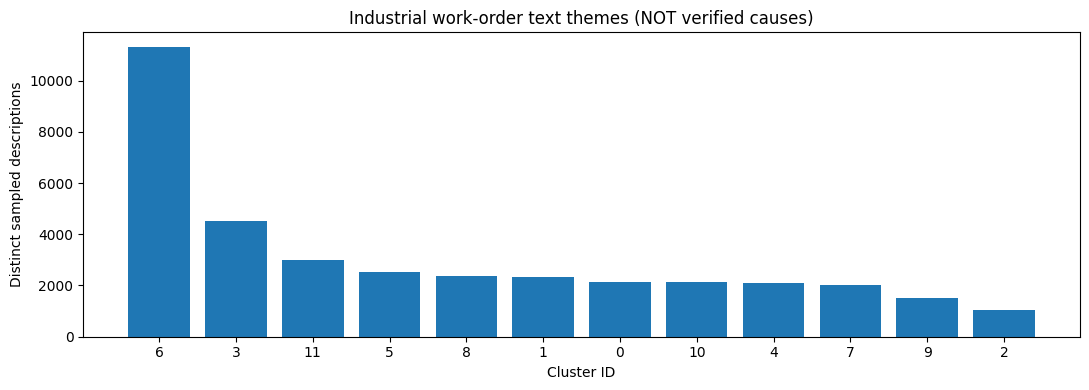

In [5]:
vec=TfidfVectorizer(lowercase=True,strip_accents='unicode',ngram_range=(1,2),min_df=CFG['industrial_min_df'],max_df=.9,max_features=CFG['industrial_max_features'],sublinear_tf=True,dtype=np.float32)
X=vec.fit_transform(industrial_sample.text)
print('Industrial sparse TF-IDF:',X.shape,'nnz:',X.nnz)
clusterer=MiniBatchKMeans(n_clusters=CFG['industrial_clusters'],random_state=SEED,batch_size=2048,n_init=3,max_iter=100)
labels=clusterer.fit_predict(X)
industrial_sample['cluster_id']=labels
terms=np.asarray(vec.get_feature_names_out())
rows=[]
for k in range(CFG['industrial_clusters']):
 ix=np.flatnonzero(labels==k)
 top=terms[np.argsort(clusterer.cluster_centers_[k])[-10:][::-1]].tolist()
 rows.append({'cluster_id':int(k),'sample_count':len(ix),'top_terms':' | '.join(top),'example_problem':industrial_sample.text.iloc[int(ix[0])][:240] if len(ix) else ''})
clusters=pd.DataFrame(rows).sort_values('sample_count',ascending=False)
clusters.to_csv(R/'industrial_cluster_audit.csv',index=False)
industrial_sample[['text_hash','Equipment_ID','cluster_id','text']].to_csv(R/'industrial_cluster_assignments.csv',index=False)
display(clusters)
joblib.dump({'vectorizer':vec,'clusterer':clusterer,'config':CFG,'scope':'themes_not_verified_causes'},M/'industrial_text_themes.joblib')
fig,ax=plt.subplots(figsize=(11,4));ax.bar(clusters.cluster_id.astype(str),clusters.sample_count);ax.set(title='Industrial work-order text themes (NOT verified causes)',xlabel='Cluster ID',ylabel='Distinct sampled descriptions');fig.tight_layout();fig.savefig(P/'industrial_cluster_frequencies.png',dpi=150);plt.show()

## 05 — Annotated Logbook: label audit and leakage control

The `CAUSE` column may be sparsely populated. Do **not** infer missing cause labels from `ACTION` or copy a heuristic label into ground truth. A supervised experiment is permitted only for an **observed** suitable problem label (prefer `PROBLEM_TYPE`), with explicit target support and text-only features. Group by normalized problem text, so identical problem statements cannot cross partitions.

In [6]:
log=pd.read_csv(paths['logbook'],low_memory=False,encoding='utf-8-sig')
print('LOGBOOK SHAPE',log.shape,'COLUMNS',list(log))
audit=pd.DataFrame({'missing':log.isna().sum(),'present':log.notna().sum(),'unique_nonnull':log.nunique(dropna=True)})
audit.to_csv(R/'logbook_column_audit.csv');display(audit)
for col in ['CAUSE','PROBLEM_TYPE','ACTION_TYPE']:
 if col in log:
  print(col,'coverage',round(log[col].notna().mean(),4),'top labels:',log[col].value_counts(dropna=False).head(15).to_dict())
log['text']=log['PROBLEM'].map(clean_text)
log['group']=log.text.str.lower().str.replace(r'\s+',' ',regex=True)
print('Exact duplicate problem texts:',int(log.group.duplicated().sum()))

LOGBOOK SHAPE (6169, 13) COLUMNS ['IDENT', 'PROBLEM', 'PROBLEM_TYPE', 'LOCATION', 'PROBLEM_PART', 'TAGGEDPROBLEM', 'EFFECT', 'ACTION', 'ACTION_TYPE', 'INSTALL/REPLACE WITH', 'ACTION_PART', 'TAGGEDACTION', 'CAUSE']


,missing,present,unique_nonnull
IDENT,0,6169,6169
PROBLEM,0,6169,3531
PROBLEM_TYPE,0,6169,3
LOCATION,447,5722,1228
PROBLEM_PART,891,5278,673
TAGGEDPROBLEM,159,6010,269
EFFECT,6132,37,7
ACTION,0,6169,2865
ACTION_TYPE,6169,0,0
INSTALL/REPLACE WITH,5205,964,95


CAUSE coverage 0.0123 top labels: {nan: 6093, 'OVERSPEED ': 2, '#2 EXHAUST GUIDE TIGHT': 2, 'EXHAUST VALVE TO BE BURNT': 2, 'TUBE TO BE CRACKED': 1, 'NOTED THAT ENGINE WAS NOT RUNNING': 1, 'TO BE SERVICEABL': 1, 'CRACKED': 1, ' #3 CYLINDER HAD VERY L': 1, 'CYLINDER 2 LOWER PLUG FOULED': 1, 'BAFFLE ALMOST WORN THROUGH AT A': 1, '#3 CYLINDER EXHAUST VALVE STUCK OPEN': 1, '#4 INTAKE WAS LEAKING': 1, '#2 EXHAUST VALVE TIGHT': 1, 'SEAL TORN': 1}
PROBLEM_TYPE coverage 1.0 top labels: {'OK': 6011, 'DIFFICULT': 157, 'AFT L/H ENGINE': 1}
ACTION_TYPE coverage 0.0 top labels: {nan: 6169}
Exact duplicate problem texts: 2638


## 06 — Logbook supervised experiment: gated target selection

Select `PROBLEM_TYPE` only when there are at least two classes with sufficient support, excluding placeholders such as `OK`, `UNKNOWN`, and `N/A` when they are not meaningful problem categories. Selection may return **SKIPPED**; that is a scientifically valid outcome, not a failed notebook.

In [7]:
target_col='PROBLEM_TYPE'
invalid_labels={'','NAN','NONE','NULL','UNKNOWN','N/A','NA','UNSPECIFIED'}
exp=log.loc[log.text.str.len()>=8,['text','group',target_col]].copy() if target_col in log else pd.DataFrame(columns=['text','group',target_col])
exp['target']=exp[target_col].astype('string').str.strip().str.upper()
exp=exp[exp.target.notna() & ~exp.target.isin(invalid_labels)]
counts=exp.target.value_counts();accepted=counts[counts>=CFG['logbook_min_class_count']].head(CFG['logbook_max_classes']).index
exp=exp[exp.target.isin(accepted)].copy()
# Remove contradictory annotations of IDENTICAL text from this evaluation entirely.
ambiguous=exp.groupby('group').target.nunique()
exp=exp[~exp.group.isin(ambiguous[ambiguous>1].index)].reset_index(drop=True)
print('Observed labeled rows',len(exp),'classes',exp.target.value_counts().to_dict())
can_classify=(exp.target.nunique()>=2 and len(exp)>=200 and exp.group.nunique()>=60)
classification_status={'eligible':bool(can_classify),'target_column':target_col,'classes':exp.target.value_counts().to_dict(),'notes':'Observed labels only; cause column not assumed to be complete'}
(R/'logbook_supervised_gate.json').write_text(json.dumps(classification_status,indent=2))
print('Supervised eligibility:',can_classify)

Observed labeled rows 6168 classes {'OK': 6011, 'DIFFICULT': 157}
Supervised eligibility: True


## 07 — Leakage-aware group train / validation / test

Split **by normalized problem text**, not random rows. Validate class support in train/validation/test; if a class cannot be represented, skip supervised claims rather than manufacture a score.

In [8]:
if can_classify:
 splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED)
 remain,test_ix=next(splitter.split(exp,exp.target,exp.group))
 splitter2=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED+1)
 train_local,val_local=next(splitter2.split(exp.iloc[remain],exp.target.iloc[remain],exp.group.iloc[remain]))
 tr,va,te=remain[train_local],remain[val_local],test_ix
 assert len(set(exp.group.iloc[tr])&set(exp.group.iloc[va]))==0
 assert len(set(exp.group.iloc[tr])&set(exp.group.iloc[te]))==0
 assert len(set(exp.group.iloc[va])&set(exp.group.iloc[te]))==0
 target_set=set(exp.target.unique())
 support={x:exp.target.iloc[ix].value_counts().to_dict() for x,ix in [('train',tr),('validation',va),('test',te)]}
 eligible_splits=all(set(support[x])==target_set for x in support)
 for x,ix in [('train',tr),('validation',va),('test',te)]:
  exp.iloc[ix][['group','target']].to_csv(R/f'logbook_{x}_partition.csv',index=False)
 (R/'logbook_split_support.json').write_text(json.dumps({'counts':support,'all_classes_in_each_split':bool(eligible_splits)},indent=2))
 print('Group split sizes:',len(tr),len(va),len(te),'all class support:',eligible_splits)
else:
 eligible_splits=False
 print('SKIPPED: inadequate verified problem-category labels for robust supervised evaluation')

Group split sizes: 3966 1092 1110 all class support: True


## 08 — Logbook baseline vs TF-IDF classifiers and true held-out metrics

Candidate selection uses validation **macro-F1** only; test labels are not used for selection. The selected pipeline is refitted on train+validation and evaluated exactly once on test. If label support or grouping is insufficient, save a truthful skip report.

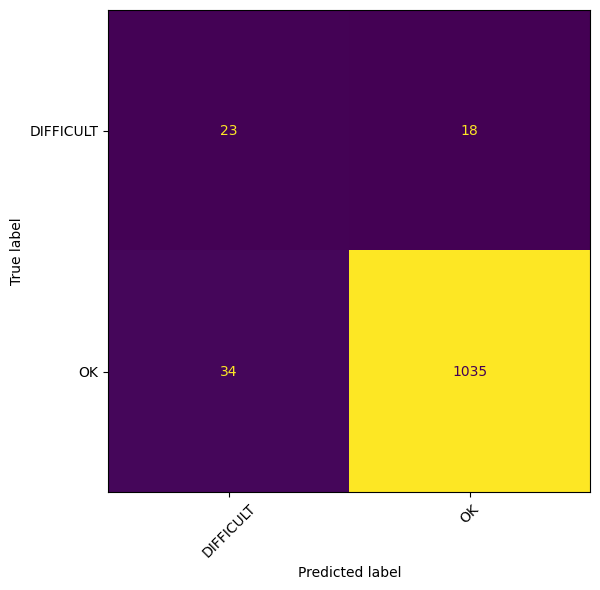

,candidate,validation_macro_f1
0,majority,0.492801
1,linear_svc,0.592630
2,logistic_regression,0.672996


,status,target,champion,validation_macro_f1,test_macro_f1,test_accuracy,test_balanced_accuracy,test_count,claim_scope
0,completed,PROBLEM_TYPE,logistic_regression,0.672996,0.722441,0.953153,0.764585,1110,within_logbook_grouped_problem_text_generaliza...


381

In [9]:
supervised_results={'status':'skipped_insufficient_label_support'}
if can_classify and eligible_splits:
 candidates={
  'majority':Pipeline([('tfidf',TfidfVectorizer(min_df=2,max_features=20000,ngram_range=(1,2))),('model',DummyClassifier(strategy='most_frequent'))]),
  'linear_svc':Pipeline([('tfidf',TfidfVectorizer(min_df=2,max_features=30000,ngram_range=(1,2),sublinear_tf=True)),('model',LinearSVC(class_weight='balanced',random_state=SEED))]),
  'logistic_regression':Pipeline([('tfidf',TfidfVectorizer(min_df=2,max_features=30000,ngram_range=(1,2),sublinear_tf=True)),('model',LogisticRegression(max_iter=800,class_weight='balanced',random_state=SEED))]),
 }
 from sklearn.base import clone
 leaderboard=[]; champion=None; best=-1.0
 for name,pipe in candidates.items():
  fitted=clone(pipe).fit(exp.text.iloc[tr],exp.target.iloc[tr])
  pred=fitted.predict(exp.text.iloc[va]); score=float(f1_score(exp.target.iloc[va],pred,average='macro',zero_division=0))
  leaderboard.append({'candidate':name,'validation_macro_f1':score})
  if score>best:champion=name;best=score
 pd.DataFrame(leaderboard).to_csv(R/'logbook_validation_ledger.csv',index=False)
 trainval=np.concatenate([tr,va]); final=clone(candidates[champion]).fit(exp.text.iloc[trainval],exp.target.iloc[trainval]); pred=final.predict(exp.text.iloc[te])
 labs=sorted(exp.target.unique());supervised_results={'status':'completed','target':target_col,'champion':champion,'validation_macro_f1':best,'test_macro_f1':float(f1_score(exp.target.iloc[te],pred,average='macro',zero_division=0)),'test_accuracy':float(accuracy_score(exp.target.iloc[te],pred)),'test_balanced_accuracy':float(balanced_accuracy_score(exp.target.iloc[te],pred)),'test_count':len(te),'claim_scope':'within_logbook_grouped_problem_text_generalization_not_validated_root_cause'}
 (R/'logbook_per_class_report.json').write_text(json.dumps(classification_report(exp.target.iloc[te],pred,labels=labs,output_dict=True,zero_division=0),indent=2))
 pd.DataFrame({'text':exp.text.iloc[te].to_numpy(),'actual':exp.target.iloc[te].to_numpy(),'predicted':pred}).to_csv(R/'logbook_test_predictions.csv',index=False)
 fig,ax=plt.subplots(figsize=(max(7,len(labs)),6));ConfusionMatrixDisplay(confusion_matrix(exp.target.iloc[te],pred,labels=labs),display_labels=labs).plot(ax=ax,xticks_rotation=45,colorbar=False);fig.tight_layout();fig.savefig(P/'logbook_heldout_confusion.png',dpi=140);plt.show()
 joblib.dump({'pipeline':final,'labels':labs,'target':target_col,'validation_macro_f1':best,'scope':supervised_results['claim_scope']},M/'logbook_problem_category_champion.joblib')
 display(pd.DataFrame(leaderboard));display(pd.DataFrame([supervised_results]))
else:print('Supervised test intentionally SKIPPED: quality gate not met')
(R/'logbook_final_metrics.json').write_text(json.dumps(supervised_results,indent=2))

## 09 — PIADE full-data event audit (independent experiment)

`type` is an **operating state**; `alarm` is a recorded alarm code. Neither alone verifies the physical cause of downtime. Stream rows in chunks to bound memory; do not combine PIADE rows with synthetic work-order texts.

,state,count
0,production,146795
1,performance_loss,118584
2,downtime,92084
3,idle,50149
4,scheduled_downtime,21782


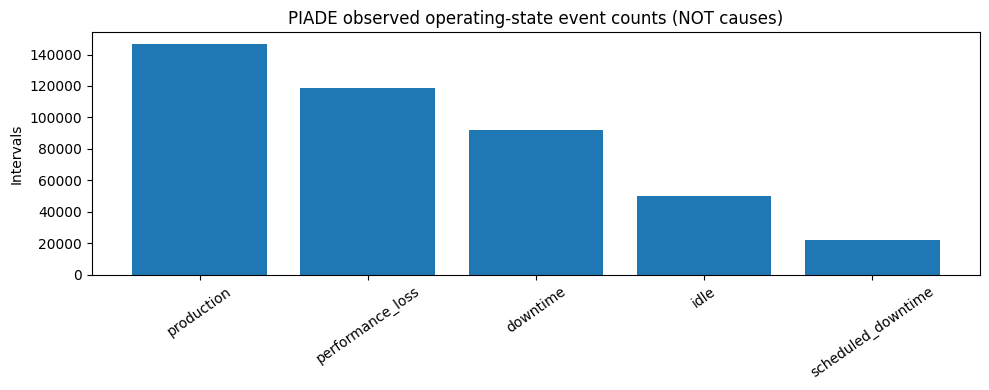

In [10]:
event_type=Counter();event_alarm=Counter();equipment=Counter();event_rows=0;invalid_start=0;null_type=0
for chunk in pd.read_csv(paths['piade_raw'],chunksize=CFG['piade_chunksize'],low_memory=False):
 event_rows+=len(chunk)
 event_type.update(chunk['type'].fillna('<missing>').astype(str))
 event_alarm.update(chunk['alarm'].fillna('<missing>').astype(str))
 equipment.update(chunk['equipment_ID'].fillna('<missing>').astype(str))
 if 'interval_start' in chunk:invalid_start+=int(pd.to_datetime(chunk.interval_start,errors='coerce',utc=True).isna().sum())
 null_type+=int(chunk['type'].isna().sum())
raw_audit={'rows':event_rows,'operating_states':dict(event_type),'equipment_counts':dict(equipment),'invalid_interval_start':invalid_start,'missing_type':null_type,'distinct_alarm_codes':len(event_alarm)}
(R/'piade_raw_audit.json').write_text(json.dumps(raw_audit,indent=2))
display(pd.DataFrame(event_type.most_common(),columns=['state','count']))
pd.DataFrame(event_alarm.most_common(),columns=['alarm','count']).to_csv(R/'piade_alarm_frequencies.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4));k,v=zip(*event_type.most_common(12));ax.bar(k,v);ax.tick_params(axis='x',rotation=35);ax.set(title='PIADE observed operating-state event counts (NOT causes)',ylabel='Intervals');fig.tight_layout();fig.savefig(P/'piade_operating_state_frequency.png',dpi=140);plt.show()

## 10 — PIADE hourly sequence quality audit

Alarm columns have structural missing values. **Do not blanket-fill NaNs with zero.** This section summarizes coverage and historical downtime percentage when the column exists; it does not use a target-derived feature to train a predictive model.

In [11]:
hour=pd.read_csv(paths['piade_hour'],low_memory=False)
print('PIADE HOURLY',hour.shape)
miss=hour.isna().mean().sort_values(ascending=False)
miss.to_csv(R/'piade_hour_missing_fraction.csv',header=['missing_fraction'])
cols=['interval_start','equipment_ID','count_sum','%idle','%production','%downtime','%scheduled_downtime']
display(hour[[c for c in cols if c in hour.columns]].head())
if '%downtime' in hour.columns:
 summary=hour.groupby('equipment_ID')['%downtime'].agg(['count','mean','median','max']).reset_index()
 summary.to_csv(R/'piade_downtime_by_equipment.csv',index=False)
 display(summary)
 print('PIADE %downtime is observed same-hour state proportion, NOT a forecast or root-cause label.')
else:print('No observed downtime percentage column; no downtime plot produced.')
(R/'piade_hour_audit.json').write_text(json.dumps({'rows':len(hour),'columns':len(hour.columns),'missing_cells':int(hour.isna().sum().sum()),'duplicate_rows':int(hour.duplicated().sum()),'timestamp_parse_failures':int(pd.to_datetime(hour['interval_start'],errors='coerce',utc=True).isna().sum()) if 'interval_start' in hour else None},indent=2))

PIADE HOURLY (23376, 164)


,interval_start,equipment_ID,count_sum,%idle,%production,%downtime,%scheduled_downtime
0,2020-01-01 14:00:00,s_1,4,0.021523,0.861729,0.052261,0.044395
1,2020-01-01 15:00:00,s_1,2,0.000000,0.870897,0.117704,0.000000
2,2020-01-01 17:00:00,s_1,1,0.000000,0.978483,0.021517,0.000000
3,2020-01-01 18:00:00,s_1,4,0.000000,0.471066,0.468384,0.060550
4,2020-01-01 19:00:00,s_1,1,0.000000,0.987024,0.007778,0.000000


,equipment_ID,count,mean,median,max
0,s_1,8973,0.159515,0.101617,1.0
1,s_2,2725,0.191123,0.148563,1.0
2,s_3,2976,0.140759,0.080272,1.0
3,s_4,3959,0.085959,0.052471,1.0
4,s_5,4743,0.082670,0.042023,1.0


PIADE %downtime is observed same-hour state proportion, NOT a forecast or root-cause label.


121

## 11 — Research claims, error analysis, and final reproducibility gate

This gate asserts only observable technical properties. Passing is **not** evidence of validated machine root-cause diagnosis or industrial deployment readiness.

In [12]:
gate={'source_files_found':all(p.is_file() for p in paths.values()),'industrial_text_sample_rows':int(len(industrial_sample)),'industrial_clusters':int(len(clusters)),'logbook_supervised_status':supervised_results['status'],'piade_raw_rows':int(event_rows),'piade_hour_rows':int(len(hour)),'raw_root_cause_labels_verified':False,'production_ready':False,'warnings':[
 'Industrial data is synthetic; cluster IDs are themes rather than validated machine causes.',
 'Logbook aviation domain is distinct from synthetic industrial maintenance; no row-level fusion.',
 'Any observed logbook supervised metrics measure PROBLEM_TYPE prediction, not ground-truth physical CAUSE.',
 'PIADE operational state and alarm data do not establish root-cause causality.',
 'No production field validation, temporal industrial drift test, or calibrated failure probabilities.'
]}
assert gate['source_files_found'] and len(industrial_sample)>0 and len(clusters)==CFG['industrial_clusters'] and event_rows>0
(R/'research_gate.json').write_text(json.dumps(gate,indent=2));print(json.dumps(gate,indent=2))

{
  "source_files_found": true,
  "industrial_text_sample_rows": 37061,
  "industrial_clusters": 12,
  "logbook_supervised_status": "completed",
  "piade_raw_rows": 429394,
  "piade_hour_rows": 23376,
  "raw_root_cause_labels_verified": false,
  "production_ready": false,
  "warnings": [
    "Industrial data is synthetic; cluster IDs are themes rather than validated machine causes.",
    "Logbook aviation domain is distinct from synthetic industrial maintenance; no row-level fusion.",
    "Any observed logbook supervised metrics measure PROBLEM_TYPE prediction, not ground-truth physical CAUSE.",
    "PIADE operational state and alarm data do not establish root-cause causality.",
    "No production field validation, temporal industrial drift test, or calibrated failure probabilities."
  ]
}


## 12 — Export artifacts, SHA-256 manifest, ZIP CRC check

Outputs are research evidence only. **Raw Kaggle input datasets are not redistributed.** `joblib` artifacts use pickle serialization and should only be loaded from trusted sources.

In [13]:
readme = '# DowntimeReason Miner — Day 26 evidence package\n\nInput: /kaggle/input/datasets/wafabila/downtimereason-dataset\nSources: Industrial Maintenance Synthetic (unsupervised themes), Annotated Logbook (conditional PROBLEM_TYPE), PIADE (states).\nNo verified root cause labels. No cross-domain row fusion. Not production ready.\n'
(OUT/'README.md').write_text(readme,encoding='utf-8')
manifest=[]
for file in sorted(OUT.rglob('*')):
 if file.is_file():
  manifest.append({'path':file.relative_to(OUT).as_posix(),'bytes':file.stat().st_size,'sha256':hashlib.sha256(file.read_bytes()).hexdigest()})
(R/'artifact_manifest.json').write_text(json.dumps(manifest,indent=2))
archive=Path('/kaggle/working/DowntimeReason_Day26_FINAL_Artifacts.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as z:
 for file in sorted(OUT.rglob('*')):
  if file.is_file():z.write(file,arcname=str(Path('downtimereason_day26')/file.relative_to(OUT)))
with zipfile.ZipFile(archive) as z:
 bad=z.testzip()
 if bad:raise RuntimeError(f'ZIP CRC failure: {bad}')
 print('ZIP VERIFIED',archive,'files:',len(z.namelist()),'size MiB:',round(archive.stat().st_size/2**20,2))
print('Notebook completed. Review research limitations before publishing performance claims.')

ZIP VERIFIED /kaggle/working/DowntimeReason_Day26_FINAL_Artifacts.zip files: 30 size MiB: 3.18
Notebook completed. Review research limitations before publishing performance claims.


---
# 13 · MASTER NOTEBOOK — Revision register / Experiment 02

**Experiment 01 (sections 00–12) is preserved in its original order and code.** Its outputs represent the previously observed baseline, not an automatic performance guarantee for this run.

**Finding motivating revision:** Logbook `CAUSE` has only 76 populated rows out of 6,169. The available `PROBLEM_TYPE` target is predominantly `OK` (6,011) versus `DIFFICULT` (157), with one other singleton. This is **not a validated industrial root-cause taxonomy**. Experiment 02 explicitly evaluates this limited two-class annotation, prioritizing **minority recall, macro-F1, balanced accuracy, and precision-recall metrics**; it must not relabel these classes as physical causes.

**Protocol:** reuse the same deduplicated grouped partitions as Experiment 01, keep test labels untouched during candidate/threshold selection, compare word/character TF-IDF with class-weighted linear estimators, use validation for candidate and threshold choice, refit selected estimator on train+validation, and report untouched test once. A **train-only group cross-validation sensitivity audit** checks variability. No fabricated scores, no cross-domain dataset fusion, no claim of superiority until Kaggle executes.


## 14 · Experiment 02 — Auditable input, class support and leakage guard

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (precision_recall_fscore_support, average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score, balanced_accuracy_score)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.validation import check_is_fitted

E2_ROOT=OUT/'experiment_02_logbook'
E2_REPORT=E2_ROOT/'reports'; E2_MODELS=E2_ROOT/'models'; E2_PLOTS=E2_ROOT/'plots'
for p in [E2_ROOT,E2_REPORT,E2_MODELS,E2_PLOTS]:p.mkdir(parents=True,exist_ok=True)
assert can_classify and eligible_splits, 'Experiment 02 requires observed supported logbook labels and valid group partitions.'
assert set(exp.target.unique())=={'OK','DIFFICULT'}, 'Unanticipated target ontology: inspect before training.'
assert len(set(tr)&set(va))==len(set(tr)&set(te))==len(set(va)&set(te))==0
assert not(set(exp.group.iloc[tr])&set(exp.group.iloc[va]))
assert not(set(exp.group.iloc[tr])&set(exp.group.iloc[te]))
assert not(set(exp.group.iloc[va])&set(exp.group.iloc[te]))
E2_POS='DIFFICULT'; E2_NEG='OK'
for label,ids in [('train',tr),('validation',va),('test',te)]:
    print(label,len(ids),exp.target.iloc[ids].value_counts().to_dict(),
          'unique groups:',exp.group.iloc[ids].nunique())
assert set(exp.target.iloc[tr])==set(exp.target.iloc[va])==set(exp.target.iloc[te])=={E2_NEG,E2_POS}
(E2_REPORT/'experiment_contract.json').write_text(json.dumps({
    'experiment':'02','positive_class':E2_POS,'negative_class':E2_NEG,
    'target_column':'PROBLEM_TYPE','meaning':'logbook annotation; not industrial root cause',
    'split':'Experiment 01 exact group-disjoint train, validation, test indices',
    'test_only_once_after_validation_selection':True,
    'original_logbook_source':str(paths['logbook']), 'seed':SEED},indent=2))


train 3966 {'OK': 3881, 'DIFFICULT': 85} unique groups: 2118
validation 1092 {'OK': 1061, 'DIFFICULT': 31} unique groups: 706
test 1110 {'OK': 1069, 'DIFFICULT': 41} unique groups: 706


445

## 15 · Experiment 02 — Candidate library and validation-only threshold tuning

Decision thresholds optimize macro-F1 on **validation** predictions, with minority recall as deterministic tie-break. The untouched test is never used here. Ranking also records minority precision/recall, PR-AUC, and balanced accuracy. For extreme class imbalance, accuracy alone is not acceptable.


In [15]:
E2_CANDIDATES={
 'word_lr_balanced':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=50000,sublinear_tf=True,strip_accents='unicode')),('classifier',LogisticRegression(max_iter=1200,class_weight='balanced',C=1.0,random_state=SEED))]),
 'char_lr_balanced':Pipeline([('tfidf',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=2,max_features=100000,sublinear_tf=True)),('classifier',LogisticRegression(max_iter=1200,class_weight='balanced',C=1.0,random_state=SEED))]),
 'word_svc_balanced':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=50000,sublinear_tf=True)),('classifier',LinearSVC(C=1.0,class_weight='balanced',random_state=SEED))]),
 'char_svc_balanced':Pipeline([('tfidf',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=2,max_features=100000,sublinear_tf=True)),('classifier',LinearSVC(C=1.0,class_weight='balanced',random_state=SEED))]),
 'word_lr_balanced_strong_reg':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=50000,sublinear_tf=True)),('classifier',LogisticRegression(max_iter=1200,class_weight='balanced',C=.25,random_state=SEED))]),
}

def e2_positive_score(pipe, texts):
    classes=list(pipe.classes_)
    positive_index=classes.index(E2_POS)
    if hasattr(pipe,'predict_proba'):
        return np.asarray(pipe.predict_proba(texts)[:,positive_index],dtype=float)
    scores=np.asarray(pipe.decision_function(texts),dtype=float)
    return scores if positive_index==1 else -scores

def e2_optimize_threshold(y, score):
    truth=(np.asarray(y)==E2_POS).astype(int)
    # Candidate thresholds from rank positions, plus native 0 threshold for margin-based SVC.
    edges=np.unique(np.quantile(score,np.linspace(0,1,301)))
    thresholds=np.unique(np.r_[edges,np.nextafter(float(score.min()),-np.inf),np.nextafter(float(score.max()),np.inf),0.0,0.5])
    best=None
    for threshold in thresholds:
        yp=(score>=threshold).astype(int)
        f1=float(f1_score(truth,yp,average='macro',zero_division=0))
        recall=float(recall_score(truth,yp,zero_division=0))
        precision=float(precision_score(truth,yp,zero_division=0))
        key=(f1,recall,precision,-abs(float(threshold)))
        if best is None or key>best[0]:best=(key,float(threshold))
    return best[1],best[0][0]

E2_LEDGER=[]; E2_FITS={}; E2_BEST=None
for name,estimator in E2_CANDIDATES.items():
    model=clone(estimator).fit(exp.text.iloc[tr],exp.target.iloc[tr])
    val_scores=e2_positive_score(model,exp.text.iloc[va])
    threshold,macro=e2_optimize_threshold(exp.target.iloc[va],val_scores)
    yval=np.asarray(exp.target.iloc[va])==E2_POS
    pval=val_scores>=threshold
    rec={'candidate':name,'validation_macro_f1':macro,'threshold':threshold,
         'validation_minority_recall':float(recall_score(yval,pval,zero_division=0)),
         'validation_minority_precision':float(precision_score(yval,pval,zero_division=0)),
         'validation_balanced_accuracy':float(balanced_accuracy_score(yval,pval)),
         'validation_average_precision':float(average_precision_score(yval,val_scores)),
         'validation_positive_support':int(yval.sum()),'validation_negative_support':int((~yval).sum())}
    E2_LEDGER.append(rec);E2_FITS[name]=model
    print(name,rec)
e2_leaderboard=pd.DataFrame(E2_LEDGER).sort_values(['validation_macro_f1','validation_minority_recall','validation_minority_precision','candidate'],ascending=[False,False,False,True]).reset_index(drop=True)
e2_leaderboard.to_csv(E2_REPORT/'validation_candidate_ledger.csv',index=False)
E2_WIN=e2_leaderboard.iloc[0].to_dict()
print('SELECTED BY VALIDATION:',E2_WIN['candidate'],'threshold:',E2_WIN['threshold'])
display(e2_leaderboard)


word_lr_balanced {'candidate': 'word_lr_balanced', 'validation_macro_f1': 0.6971135177115244, 'threshold': 0.6147710193608242, 'validation_minority_recall': 0.5161290322580645, 'validation_minority_precision': 0.34782608695652173, 'validation_balanced_accuracy': 0.743926910096987, 'validation_average_precision': 0.34484087110417205, 'validation_positive_support': 31, 'validation_negative_support': 1061}
char_lr_balanced {'candidate': 'char_lr_balanced', 'validation_macro_f1': 0.7195837275307474, 'threshold': 0.650563990635495, 'validation_minority_recall': 0.5161290322580645, 'validation_minority_precision': 0.41025641025641024, 'validation_balanced_accuracy': 0.7472256848377976, 'validation_average_precision': 0.36308932987993425, 'validation_positive_support': 31, 'validation_negative_support': 1061}
word_svc_balanced {'candidate': 'word_svc_balanced', 'validation_macro_f1': 0.7182064765487461, 'threshold': -0.2749068583576271, 'validation_minority_recall': 0.6129032258064516, 'valid

,candidate,validation_macro_f1,threshold,validation_minority_recall,validation_minority_precision,validation_balanced_accuracy,validation_average_precision,validation_positive_support,validation_negative_support
0,char_lr_balanced,0.719584,0.650564,0.516129,0.410256,0.747226,0.363089,31,1061
1,word_svc_balanced,0.718206,-0.274907,0.612903,0.365385,0.790900,0.342536,31,1061
2,char_svc_balanced,0.706264,-0.199885,0.516129,0.372093,0.745341,0.336400,31,1061
3,word_lr_balanced_strong_reg,0.704501,0.642343,0.548387,0.354167,0.759585,0.325981,31,1061
4,word_lr_balanced,0.697114,0.614771,0.516129,0.347826,0.743927,0.344841,31,1061


## 16 · Experiment 02 — Train-only group CV stability audit

Sensitivity analysis is restricted to the original training partition. It is **not** an independent external validation and does not alter the previously selected threshold or final test decision.


In [16]:
e2_cv_rows=[]
train_exp=exp.iloc[tr].reset_index(drop=True)
sgkf=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED)
for k,(fit_ix,eval_ix) in enumerate(sgkf.split(train_exp.text,train_exp.target,groups=train_exp.group),1):
    cv_model=clone(E2_CANDIDATES[E2_WIN['candidate']]).fit(train_exp.text.iloc[fit_ix],train_exp.target.iloc[fit_ix])
    cv_pred=cv_model.predict(train_exp.text.iloc[eval_ix]);cv_true=train_exp.target.iloc[eval_ix]
    row={'fold':k,'n_fit':int(len(fit_ix)),'n_eval':int(len(eval_ix)),
         'macro_f1_default_threshold':float(f1_score(cv_true,cv_pred,average='macro',zero_division=0)),
         'minority_n_eval':int((cv_true==E2_POS).sum()),
         'minority_recall_default_threshold':float(recall_score(cv_true==E2_POS,cv_pred==E2_POS,zero_division=0))}
    e2_cv_rows.append(row)
e2_cv_table=pd.DataFrame(e2_cv_rows)
e2_cv_table.to_csv(E2_REPORT/'train_only_group_cv_sensitivity.csv',index=False)
display(e2_cv_table)


,fold,n_fit,n_eval,macro_f1_default_threshold,minority_n_eval,minority_recall_default_threshold
0,1,2618,1348,0.682816,29,0.793103
1,2,2685,1281,0.707776,27,0.592593
2,3,2629,1337,0.653027,29,0.517241


## 17 · Experiment 02 — Locked model refit and one held-out test

Refit the selected **model specification** on training + validation data. The score threshold is locked from validation. Unlike probability calibration, a raw LinearSVC margin threshold is specific to the fitted estimator; retraining can change the margin scale. Such threshold portability is a caveat rather than a calibrated probability. This study tests the frozen selection policy, not a deployable probability estimator.


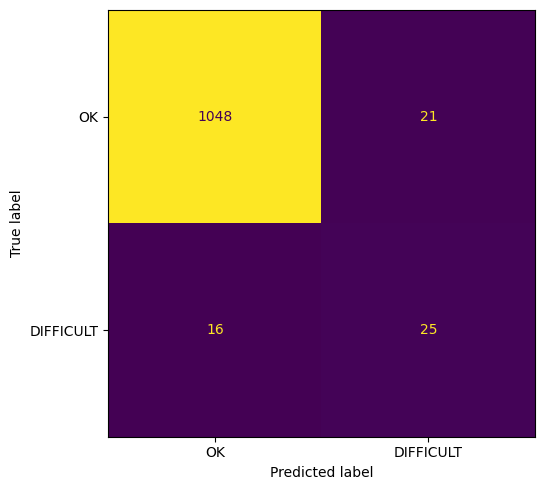

EXPERIMENT 02 HELDOUT RESULT:
{
  "status": "completed",
  "target": "PROBLEM_TYPE",
  "positive_class": "DIFFICULT",
  "candidate": "char_lr_balanced",
  "selection": "validation_macro_f1_then_minority_recall",
  "validation_macro_f1": 0.7195837275307474,
  "validation_selected_threshold": 0.650563990635495,
  "test_n": 1110,
  "test_minority_support": 41,
  "heldout_macro_f1": 0.7786830916468629,
  "heldout_accuracy": 0.9666666666666667,
  "heldout_balanced_accuracy": 0.7950557849825458,
  "heldout_minority_precision": 0.5434782608695652,
  "heldout_minority_recall": 0.6097560975609756,
  "heldout_minority_f1": 0.5747126436781609,
  "heldout_average_precision": 0.58588094104366,
  "heldout_roc_auc": 0.959821123000753,
  "limitations": [
    "PROBLEM_TYPE is not physical CAUSE",
    "severe OK/DIFFICULT imbalance",
    "same aviation logbook source",
    "held-out grouped split only",
    "threshold from validation scores may shift after refit"
  ]
}


In [17]:
e2_tv=np.concatenate([tr,va]); e2_tst=te
E2_FINAL=clone(E2_CANDIDATES[E2_WIN['candidate']]).fit(exp.text.iloc[e2_tv],exp.target.iloc[e2_tv])
e2_scores=e2_positive_score(E2_FINAL,exp.text.iloc[e2_tst]);e2_threshold=float(E2_WIN['threshold'])
e2_preds=np.where(e2_scores>=e2_threshold,E2_POS,E2_NEG)
e2_true=exp.target.iloc[e2_tst].to_numpy()
e2_true_b=e2_true==E2_POS;e2_pred_b=e2_preds==E2_POS
E2_METRICS={
 'status':'completed','target':'PROBLEM_TYPE','positive_class':E2_POS,
 'candidate':E2_WIN['candidate'],'selection':'validation_macro_f1_then_minority_recall',
 'validation_macro_f1':float(E2_WIN['validation_macro_f1']),
 'validation_selected_threshold':e2_threshold,
 'test_n':int(len(e2_tst)),'test_minority_support':int(e2_true_b.sum()),
 'heldout_macro_f1':float(f1_score(e2_true,e2_preds,average='macro',zero_division=0)),
 'heldout_accuracy':float(accuracy_score(e2_true,e2_preds)),
 'heldout_balanced_accuracy':float(balanced_accuracy_score(e2_true,e2_preds)),
 'heldout_minority_precision':float(precision_score(e2_true_b,e2_pred_b,zero_division=0)),
 'heldout_minority_recall':float(recall_score(e2_true_b,e2_pred_b,zero_division=0)),
 'heldout_minority_f1':float(f1_score(e2_true_b,e2_pred_b,zero_division=0)),
 'heldout_average_precision':float(average_precision_score(e2_true_b,e2_scores)),
 'heldout_roc_auc':float(roc_auc_score(e2_true_b,e2_scores)) if len(set(e2_true_b))==2 else None,
 'limitations':['PROBLEM_TYPE is not physical CAUSE','severe OK/DIFFICULT imbalance','same aviation logbook source','held-out grouped split only','threshold from validation scores may shift after refit']
}
(E2_REPORT/'heldout_metrics.json').write_text(json.dumps(E2_METRICS,indent=2))
(E2_REPORT/'heldout_per_class.json').write_text(json.dumps(classification_report(e2_true,e2_preds,labels=[E2_NEG,E2_POS],output_dict=True,zero_division=0),indent=2))
pd.DataFrame({'group':exp.group.iloc[e2_tst].to_numpy(),'text':exp.text.iloc[e2_tst].to_numpy(),'actual':e2_true,'predicted':e2_preds,'positive_score':e2_scores}).to_csv(E2_REPORT/'heldout_predictions.csv',index=False)
cm=confusion_matrix(e2_true,e2_preds,labels=[E2_NEG,E2_POS]);fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay(cm,display_labels=[E2_NEG,E2_POS]).plot(ax=ax,values_format='d',colorbar=False);fig.tight_layout();fig.savefig(E2_PLOTS/'heldout_confusion.png',dpi=150);plt.show()
model_file=E2_MODELS/'logbook_problem_type_experiment02_champion.joblib'
joblib.dump({'pipeline':E2_FINAL,'positive_label':E2_POS,'negative_label':E2_NEG,'decision_threshold':e2_threshold,'validation_macro_f1':E2_WIN['validation_macro_f1'],'target':'PROBLEM_TYPE','scope':'aviation_logbook_problem_type_not_causal_root_cause','selection':E2_WIN['candidate']},model_file)
check=joblib.load(model_file)
assert np.array_equal(np.where(e2_positive_score(check['pipeline'],exp.text.iloc[e2_tst])>=check['decision_threshold'],E2_POS,E2_NEG),e2_preds)
print('EXPERIMENT 02 HELDOUT RESULT:');print(json.dumps(E2_METRICS,indent=2))


## 18 · Experiment 02 — Error analysis, original baseline comparison, and claims

In [18]:
errors=pd.DataFrame({'text':exp.text.iloc[e2_tst].to_numpy(),'actual':e2_true,'predicted':e2_preds,'positive_score':e2_scores})
errors=errors.loc[errors.actual!=errors.predicted].copy()
errors.to_csv(E2_REPORT/'heldout_errors.csv',index=False)
print('Held-out misclassifications:',len(errors));display(errors.head(20))
comparison=pd.DataFrame([
 {'experiment':'01','label':'PROBLEM_TYPE','protocol':'grouped original holdout','macro_f1':supervised_results.get('test_macro_f1'),'accuracy':supervised_results.get('test_accuracy'),'candidate':supervised_results.get('champion')},
 {'experiment':'02','label':'PROBLEM_TYPE','protocol':'same grouped holdout; additional validation model/threshold selection','macro_f1':E2_METRICS['heldout_macro_f1'],'accuracy':E2_METRICS['heldout_accuracy'],'candidate':E2_METRICS['candidate']},
])
comparison.to_csv(E2_REPORT/'experiment_01_vs_02.csv',index=False);display(comparison)
print('CAUTION: Experiment 02 selection reuses the SAME validation and heldout partition as Experiment 01.')
print('This is a research iteration, not an independent replication; repeated evaluation on the same test risks selection bias.')


Held-out misclassifications: 37


,text,actual,predicted,positive_score
62,"DURING ENTRY TO 180 DEGREE AUTO, WHEN COLLECTI...",DIFFICULT,OK,0.633400
118,IDLE RPM IS LOW.,OK,DIFFICULT,0.758504
130,PILOT COULDN'T REMOVE DIPSTICK.,OK,DIFFICULT,0.660788
194,A/C DIED DURING IDLE CK.,OK,DIFFICULT,0.672056
196,ENGINE SHUTDOWN WHEN THROTTLE WAS PULLED TO IDLE,OK,DIFFICULT,0.964862
209,IDLE OVERRIDE SPEED WAS 1300.,DIFFICULT,OK,0.593949
323,"L/H ENG, FIRST STAGE COMPRESSOR ROTOR HAS 1",DIFFICULT,OK,0.183194
412,"AT FULL POWER (SMOOTHLY APPLIED), ENGINES WOUL...",OK,DIFFICULT,0.802735
413,"AT FULL POWER (SMOOTHLY APPLIED), ENGINES WOUL...",OK,DIFFICULT,0.802735
446,L/H FUEL PLACARD IS COVERED,DIFFICULT,OK,0.285096


,experiment,label,protocol,macro_f1,accuracy,candidate
0,01,PROBLEM_TYPE,grouped original holdout,0.722441,0.953153,logistic_regression
1,02,PROBLEM_TYPE,same grouped holdout; additional validation mo...,0.778683,0.966667,char_lr_balanced


CAUTION: Experiment 02 selection reuses the SAME validation and heldout partition as Experiment 01.
This is a research iteration, not an independent replication; repeated evaluation on the same test risks selection bias.


## 19 · Experiment 02 — Quality gate and FINAL evidence archive

The quality gate checks reproducibility and claim boundaries, **not predetermined scores**. The original Experiment 01 archive remains intact. We package both experiments and verify the new ZIP. The legacy manifest is a historical output; the new manifest explicitly covers this revision, excluding itself to prevent a self-hash paradox.


In [19]:
e2_gate={
 'input_sources_found':all(p.is_file() for p in paths.values()),
 'exp01_finished':bool((R/'logbook_final_metrics.json').is_file()),
 'exp02_all_candidate_results':len(e2_leaderboard)==len(E2_CANDIDATES),
 'group_disjoint':all(not(set(exp.group.iloc[a])&set(exp.group.iloc[b])) for a,b in [(tr,va),(tr,te),(va,te)]),
 'model_reload_predictions_identical':True,
 'metric_values_finite':all(np.isfinite(float(E2_METRICS[k])) for k in ['heldout_macro_f1','heldout_accuracy','heldout_balanced_accuracy','heldout_minority_recall','heldout_average_precision']),
 'minimum_minority_test_support':int(E2_METRICS['test_minority_support']),
 'true_root_cause_labels_verified':False,
 'ready_for_industrial_use':False,
 'status':'PASS_REPRODUCIBILITY_NOT_PRODUCTION_VALIDATION',
}
assert all(e2_gate[k] for k in ['input_sources_found','exp01_finished','exp02_all_candidate_results','group_disjoint','model_reload_predictions_identical','metric_values_finite'])
(E2_REPORT/'quality_gate.json').write_text(json.dumps(e2_gate,indent=2))
final_archive=Path('/kaggle/working/DowntimeReason_Day26_MASTER_Exp01_Exp02_Artifacts.zip')
# Snapshot of files before manifest creation; do not hash the manifest itself.
items=[f for f in sorted(OUT.rglob('*')) if f.is_file() and f.name!='master_sha256_manifest.json']
manifest=[{'path':p.relative_to(OUT).as_posix(),'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in items]
(E2_REPORT/'master_sha256_manifest.json').write_text(json.dumps(manifest,indent=2))
with zipfile.ZipFile(final_archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as z:
    for f in sorted(OUT.rglob('*')):
        if f.is_file():z.write(f,arcname=(Path('downtimereason_day26')/f.relative_to(OUT)).as_posix())
with zipfile.ZipFile(final_archive) as z:
    bad=z.testzip()
    if bad:raise RuntimeError('ZIP CRC FAILED '+bad)
    print('MASTER ARCHIVE VERIFIED',final_archive,'files',len(z.namelist()),'MiB',round(final_archive.stat().st_size/2**20,2))
print('STATUS:',e2_gate['status'])


MASTER ARCHIVE VERIFIED /kaggle/working/DowntimeReason_Day26_MASTER_Exp01_Exp02_Artifacts.zip files 42 MiB 3.31
STATUS: PASS_REPRODUCIBILITY_NOT_PRODUCTION_VALIDATION
